# Fraud penalty: merchant risk tiers and expected fraud loss

This notebook turns the supplied fraud scores into something the ranking can use. No trained model feeds the penalty: it prices the observed scores directly. (The classifiers that explain what the scores respond to are in `fraud_models.ipynb`.)

| Part | What it does | Output |
|---|---|---|
| A (§2–6) | Merchant-level summary features, a classifier for "does this merchant get scored at all?", and a risk tier per merchant | `merchant_risk` |
| B (§7–9) | Expected fraud loss in dollars, subtracted from each merchant's estimated BNPL revenue; the `merchant_ranking_v2` score is recomputed | `merchant_ranking_v2_fraud_adjusted.parquet`, `top100_v2_fraud_adjusted.csv` |

The merchant score table has only 114 scored merchant-days across 61 merchants. As with consumers, a score marks a pre-screened day (the lowest score is 18%). Having no score is not proof a merchant is clean.

**Run order:** `scripts/join_external_sa2.py` → `01_data_quality_eda.ipynb` → `merchant_ranking_v2.ipynb` → this notebook.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score
from xgboost import XGBClassifier

# Works when launched from the repository, project2, or notebooks directory.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if p.name == "project2"), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd() / "project2"
PROCESSED_PATH = PROJECT_ROOT / "data" / "tables" / "processed"
if not PROCESSED_PATH.is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to your project2 directory.")
RANKING_IN = PROCESSED_PATH / "merchant_ranking_v2.parquet"
if not RANKING_IN.exists():
    raise FileNotFoundError(f"{RANKING_IN} is missing - see the run order above.")
RANDOM_STATE = 42
CUTOFFS = [30, 50, 70]
# Scores exist only in this window; features are computed over the same period.
START, END = "2021-02-28", "2022-02-27"
# Without a cap, XGBoost oversubscribes the CPU alongside Spark and slows to a crawl.
XGB_THREADS = 4
spark = SparkSession.builder.config("spark.driver.memory", "6g").getOrCreate()

## Part A: merchant risk tiers

## 2. Merchant-day aggregates

In [2]:
trans = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    .withColumn("order_date", F.to_date("order_datetime"))
    .where(F.col("order_date").between(START, END))
    .withColumn("day_txn_count", F.count("*").over(Window.partitionBy("user_id", "order_date")))
)

merchant_w = Window.partitionBy("merchant_abn")
merchant_day = (
    trans.groupBy("merchant_abn", "order_date")
    .agg(F.sum("dollar_value").alias("revenue"), F.count("*").alias("txn_count"),
         F.mean("dollar_value").alias("avg_value"), F.max("dollar_value").alias("max_value"))
    # Each day relative to that merchant's typical (median) day.
    .withColumn("revenue_ratio", F.col("revenue") / F.percentile_approx("revenue", 0.5).over(merchant_w))
    .withColumn("count_ratio", F.col("txn_count") / F.percentile_approx("txn_count", 0.5).over(merchant_w))
    .withColumn("avg_value_ratio", F.col("avg_value") / F.percentile_approx("avg_value", 0.5).over(merchant_w))
    .withColumn("typical_revenue", F.percentile_approx("revenue", 0.5).over(merchant_w))
).cache()

## 3. What drives a merchant-day score?

This correlates each scored day's features with its score.

In [3]:
merchant_scores = (spark.read.parquet(str(PROCESSED_PATH / "merchant_fraud_probability"))
                   .withColumn("order_date", F.to_date("order_datetime")).drop("order_datetime"))
scored_days = merchant_scores.join(merchant_day, ["merchant_abn", "order_date"], "left").toPandas()
assert scored_days["revenue"].notna().all(), "every scored day should match transactions"

DAY_COLS = ["revenue", "txn_count", "avg_value", "revenue_ratio", "count_ratio",
            "avg_value_ratio", "typical_revenue"]
pd.Series({c: spearmanr(scored_days[c], scored_days["fraud_probability"]).statistic
           for c in DAY_COLS}, name="Spearman with score").round(2)

revenue           -0.00
txn_count         -0.27
avg_value          0.09
revenue_ratio      0.72
count_ratio        0.03
avg_value_ratio    0.69
typical_revenue   -0.55
Name: Spearman with score, dtype: float64

- **Relative spikes drive the score.** The score tracks revenue and average value relative to the merchant's usual day. Raw revenue alone does not.
- **The highest scores are single oversized transactions.** They fall on days with a normal transaction count but a much larger average value.
- **Scored days are also large in absolute terms.** Most have $40K–$60K of revenue, versus a typical merchant day under $1K.
- **Not every spike gets scored.** The cell below shows that scored days are only a subset of similar days.

In [4]:
day_pd = merchant_day.select("revenue", "revenue_ratio").toPandas()
print(f"Merchant-days with revenue >= $40K: {(day_pd['revenue'] >= 40_000).sum():,}; "
      f"scored: {(scored_days['revenue'] >= 40_000).sum():,}")

Merchant-days with revenue >= $40K: 186; scored: 100


## 4. Merchant-level summary features

The features are computed over the scoring window. None of them use the merchant scores.

| Group | Features |
|---|---|
| Transaction spread | coefficient of variation (standard deviation ÷ mean), 99th percentile ÷ median, max ÷ median |
| Daily volatility | coefficient of variation of daily revenue and of daily transaction count |
| Spikes | largest daily revenue ratio and largest average-value ratio; number of days where either is ≥ 3× the merchant's median |
| Size | transaction count, mean transaction value, median and max daily revenue, active days, take rate |
| Customers | repeat-customer share |
| Consumer-flag exposure | transactions on consumer-scored days with score ≥ 30 and ≥ 50, weighted 1 ÷ the user's transactions that day, as in `fraud_models.ipynb` |

In [5]:
consumer_score = F.col("consumer_fraud_probability")
day_weight = 1.0 / F.col("day_txn_count")
txn_stats = trans.groupBy("merchant_abn").agg(
    F.count("*").alias("txn_count"), F.countDistinct("user_id").alias("distinct_users"),
    F.countDistinct("order_date").alias("active_days"),
    F.mean("dollar_value").alias("txn_mean"), F.stddev("dollar_value").alias("txn_std"),
    F.percentile_approx("dollar_value", 0.5).alias("txn_median"),
    F.percentile_approx("dollar_value", 0.99).alias("txn_p99"), F.max("dollar_value").alias("txn_max"),
    *[F.sum(F.when(consumer_score >= k, day_weight).otherwise(0)).alias(f"consumer_flag_ge{k}")
      for k in (30, 50)],
)
day_stats = merchant_day.groupBy("merchant_abn").agg(
    F.mean("revenue").alias("day_rev_mean"), F.stddev("revenue").alias("day_rev_std"),
    F.percentile_approx("revenue", 0.5).alias("day_rev_median"), F.max("revenue").alias("day_rev_max"),
    F.mean("txn_count").alias("day_n_mean"), F.stddev("txn_count").alias("day_n_std"),
    F.max("revenue_ratio").alias("day_rev_ratio_max"),
    F.max("avg_value_ratio").alias("day_avg_value_ratio_max"),
    F.sum((F.col("revenue_ratio") >= 3).cast("int")).alias("days_rev_ratio_ge3"),
    F.sum((F.col("avg_value_ratio") >= 3).cast("int")).alias("days_avg_value_ratio_ge3"),
)
merchant = txn_stats.join(day_stats, "merchant_abn").toPandas()

labels = scored_days.groupby("merchant_abn")["fraud_probability"].agg(
    merchant_score_max="max", merchant_scored_days="size").reset_index()
merchant_info = pd.read_parquet(PROCESSED_PATH / "merchants_clean",
                                columns=["merchant_abn", "name", "revenue_code", "take_rate"])
merchant = (merchant.merge(labels, on="merchant_abn", how="left")
            .merge(merchant_info, on="merchant_abn", how="left"))
merchant["flagged"] = merchant["merchant_score_max"].notna().astype(int)

merchant["txn_cv"] = merchant["txn_std"] / merchant["txn_mean"]
merchant["txn_p99_to_median"] = merchant["txn_p99"] / merchant["txn_median"]
merchant["txn_max_to_median"] = merchant["txn_max"] / merchant["txn_median"]
merchant["day_rev_cv"] = merchant["day_rev_std"] / merchant["day_rev_mean"]
merchant["day_n_cv"] = merchant["day_n_std"] / merchant["day_n_mean"]
merchant["repeat_share"] = 1 - merchant["distinct_users"] / merchant["txn_count"]
merchant["consumer_flag_share_ge50"] = merchant["consumer_flag_ge50"] / merchant["txn_count"]
for col in ["txn_count", "txn_mean", "day_rev_median", "day_rev_max",
            "consumer_flag_ge30", "consumer_flag_ge50"]:
    merchant[f"log_{col}"] = np.log1p(merchant[col])

print(f"{len(merchant):,} merchants active in the window; {merchant['flagged'].sum()} have a merchant score "
      f"({merchant.loc[merchant['flagged'] == 1, 'revenue_code'].isna().sum()} of those are missing from merchants_clean)")

4,414 merchants active in the window; 61 have a merchant score (13 of those are missing from merchants_clean)


In [6]:
SPREAD = ["txn_cv", "txn_p99_to_median", "txn_max_to_median", "day_rev_cv", "day_n_cv",
          "day_rev_ratio_max", "day_avg_value_ratio_max", "days_rev_ratio_ge3", "days_avg_value_ratio_ge3"]
SIZE = ["log_txn_count", "log_txn_mean", "log_day_rev_median", "log_day_rev_max",
        "active_days", "repeat_share", "take_rate"]
CONSUMER = ["log_consumer_flag_ge30", "log_consumer_flag_ge50", "consumer_flag_share_ge50"]

merchant.groupby("flagged")[SPREAD + ["txn_mean", "day_rev_median", "day_rev_max", "consumer_flag_ge50"]] \
    .median().T.rename(columns={0: "unscored (median)", 1: "scored (median)"}).round(2)

flagged,unscored (median),scored (median)
txn_cv,0.69,0.73
txn_p99_to_median,3.70,3.96
txn_max_to_median,4.66,6.07
day_rev_cv,0.67,0.76
day_n_cv,0.39,0.31
day_rev_ratio_max,4.11,4.69
day_avg_value_ratio_max,3.26,3.49
days_rev_ratio_ge3,3.00,2.00
days_avg_value_ratio_ge3,1.00,1.00
txn_mean,338.47,3734.31


## 5. Which merchants get scored?

The target is whether a merchant has at least one merchant score. There are about 61 positives out of about 4,400 merchants. Each feature set is evaluated with 5-fold stratified cross-validation, repeated over 5 seeds. The PR-AUC of a random ranking equals the prevalence.

In [7]:
def make_model():
    return XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=2,
                         subsample=0.8, colsample_bytree=0.8, n_jobs=XGB_THREADS,
                         random_state=RANDOM_STATE)

def out_of_fold(features, seeds=range(5)):
    # Out-of-fold predictions, averaged over repeats, so no merchant is scored
    # by a model that saw its own label.
    y = merchant["flagged"]
    preds = [cross_val_predict(make_model(), merchant[features], y, method="predict_proba",
                               cv=StratifiedKFold(5, shuffle=True, random_state=s))[:, 1] for s in seeds]
    ap = [average_precision_score(y, p) for p in preds]
    return np.mean(preds, axis=0), {"PR-AUC": np.mean(ap), "PR-AUC sd": np.std(ap),
                                    "ROC-AUC": np.mean([roc_auc_score(y, p) for p in preds])}

results, oof = {}, {}
for name, features in {"spread only": SPREAD, "spread + size": SPREAD + SIZE,
                       "spread + size + consumer flags": SPREAD + SIZE + CONSUMER}.items():
    oof[name], results[name] = out_of_fold(features)
results = pd.DataFrame(results).T.assign(prevalence=merchant["flagged"].mean())
results.round(3)

,PR-AUC,PR-AUC sd,ROC-AUC,prevalence
spread only,0.153,0.006,0.803,0.014
spread + size,0.757,0.036,0.997,0.014
spread + size + consumer flags,0.766,0.032,0.997,0.014


- **Spread features alone** rank flagged merchants about 10× better than random, but they're weak on their own.
- **Size is what separates scored merchants.** They are big-ticket merchants: much higher mean transaction and typical daily revenue. The scoring appears to fire on large-revenue spike days, and small merchants rarely reach those amounts.
- **Consumer-flag exposure** adds a little on top.

**Caution for the ranking.** A model that relies on size will also mark large, legitimate, high-value merchants as risky. Use the probability as a prompt for review, and keep size out of any penalty applied to the ranking itself.

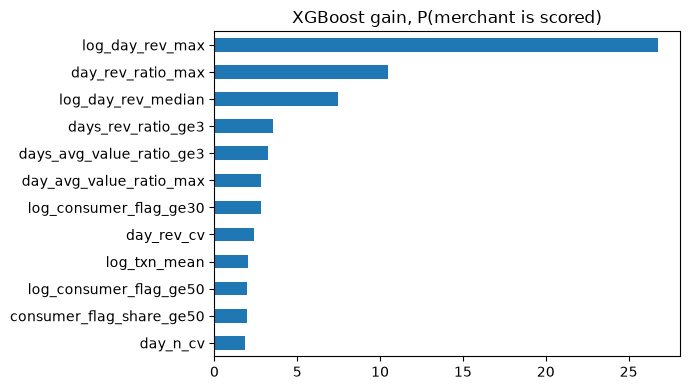

In [8]:
FEATURES = SPREAD + SIZE + CONSUMER
merchant["p_flagged"] = oof["spread + size + consumer flags"]
final_model = make_model().fit(merchant[FEATURES], merchant["flagged"])
gain = pd.Series(final_model.get_booster().get_score(importance_type="gain")).sort_values()
gain.tail(12).plot.barh(figsize=(7, 4), title="XGBoost gain, P(merchant is scored)")
plt.tight_layout()
plt.show()

## 6. Merchant risk table

| `risk_tier` | Rule |
|---|---|
| `high` | highest merchant score ≥ 70 |
| `flagged` | highest merchant score 50–70 |
| `watch` | highest merchant score 30–50 |
| `scored_low` | scored, but every score < 30 |
| `suspect` | never scored, but out-of-fold P(scored) ≥ `SUSPECT_THRESHOLD` |
| `none` | everything else |

The suspect threshold is a default. Check how many merchants it picks up and adjust it.

In [9]:
SUSPECT_THRESHOLD = 0.5
s = merchant["merchant_score_max"]
merchant["risk_tier"] = np.select(
    [s >= 70, s >= 50, s >= 30, s.notna(), merchant["p_flagged"] >= SUSPECT_THRESHOLD],
    ["high", "flagged", "watch", "scored_low", "suspect"], "none")
print(merchant["risk_tier"].value_counts().reindex(
    ["high", "flagged", "watch", "scored_low", "suspect", "none"]).to_string())

RISK_COLS = ["merchant_abn", "name", "revenue_code", "risk_tier", "merchant_score_max",
             "merchant_scored_days", "p_flagged", "consumer_flag_ge30", "consumer_flag_ge50",
             "consumer_flag_share_ge50", *SPREAD, "txn_count", "txn_mean", "day_rev_median"]
merchant_risk = merchant[RISK_COLS].sort_values(["merchant_score_max", "p_flagged"], ascending=False)
merchant_risk.head(15)

risk_tier
high             7
flagged         18
watch           21
scored_low      15
suspect         13
none          4340


,merchant_abn,name,revenue_code,risk_tier,merchant_score_max,merchant_scored_days,p_flagged,consumer_flag_ge30,consumer_flag_ge50,consumer_flag_share_ge50,...,txn_max_to_median,day_rev_cv,day_n_cv,day_rev_ratio_max,day_avg_value_ratio_max,days_rev_ratio_ge3,days_avg_value_ratio_ge3,txn_count,txn_mean,day_rev_median
510,82999039227,NaN,NaN,high,94.134700,1.0,0.898578,16.916667,8.166667,0.154088,...,5.667852,0.874994,0.255763,5.594423,5.634548,4,2,53,17706.100469,13821.062820
1555,35575706403,Tempus Mauris Ltd,b,high,91.096068,1.0,0.215880,6.750000,1.083333,0.025194,...,5.673314,0.757244,0.302736,5.012379,5.632460,1,3,43,11311.677359,10017.100322
465,97884414539,Ut Corporation,a,high,89.799200,1.0,0.132127,5.583333,0.833333,0.023810,...,5.346533,0.858785,0.228460,5.346533,5.346533,5,3,35,11765.722789,8344.664840
3648,14530561097,Duis At Inc.,c,high,80.800545,1.0,0.870959,24.166667,6.583333,0.056268,...,4.490281,0.634877,0.295396,4.072188,4.437201,3,2,117,11384.291120,11296.419159
4257,23686790459,NaN,NaN,high,79.454344,1.0,0.864620,8.833333,3.750000,0.150000,...,4.694712,0.729809,0.195959,4.694712,4.694712,1,1,25,18267.239660,14421.914155
2694,18737319630,Ut Industries,a,high,72.730697,1.0,0.164365,0.000000,0.000000,0.000000,...,17.076649,1.247098,0.419006,15.863995,7.533129,19,19,122,198.814032,142.498826
1317,85482742429,Mi Eleifend Egestas LLP,b,high,70.881311,1.0,0.378885,0.000000,0.000000,0.000000,...,7.122421,0.902659,0.584836,11.383527,3.253903,12,2,325,67.786220,81.347771
2053,78080443264,Nullam Enim Sed Incorporated,e,flagged,69.095317,1.0,0.129649,0.000000,0.000000,0.000000,...,7.230800,0.854473,0.617093,10.665998,6.483203,15,15,630,20.164037,35.213883
636,83199298021,Ligula Elit Pretium Foundation,b,flagged,69.085569,6.0,0.969662,31.366667,17.416667,0.167468,...,4.052974,0.692968,0.391043,4.773511,3.850245,3,2,104,18667.470066,19717.146839
411,76968105359,Nec Limited,a,flagged,68.278436,1.0,0.299523,0.000000,0.000000,0.000000,...,10.715651,1.031426,0.570327,11.223797,6.498291,18,9,431,288.322956,376.142871


In [10]:
merchant_risk[merchant_risk["risk_tier"] == "suspect"].sort_values("p_flagged", ascending=False).head(15)

,merchant_abn,name,revenue_code,risk_tier,merchant_score_max,merchant_scored_days,p_flagged,consumer_flag_ge30,consumer_flag_ge50,consumer_flag_share_ge50,...,txn_max_to_median,day_rev_cv,day_n_cv,day_rev_ratio_max,day_avg_value_ratio_max,days_rev_ratio_ge3,days_avg_value_ratio_ge3,txn_count,txn_mean,day_rev_median
1243,58495294020,Diam Nunc Associates,b,suspect,NaN,NaN,0.967938,13.450000,1.500000,0.028846,...,4.282711,0.672102,0.228251,3.969260,4.111548,1,1,52,14995.571145,14496.805852
3487,87901668493,NaN,NaN,suspect,NaN,NaN,0.913098,9.783333,3.833333,0.062842,...,4.814570,0.743051,0.264151,4.787572,3.011675,2,1,61,11770.153702,10485.703322
4046,53714166188,NaN,NaN,suspect,NaN,NaN,0.886556,7.083333,0.000000,0.000000,...,12.396300,1.024850,0.433931,10.787023,6.473386,16,13,193,4642.206939,4049.947334
2101,86868464441,NaN,NaN,suspect,NaN,NaN,0.816476,0.500000,0.500000,0.500000,...,1.000000,NaN,NaN,1.000000,1.000000,0,0,1,47422.851460,47422.851460
1432,44345785419,Phasellus Nulla LLC,a,suspect,NaN,NaN,0.806636,11.226190,3.333333,0.057471,...,3.031860,0.602848,0.246119,3.668675,3.233116,3,1,58,15048.641768,13525.131262
631,54860127682,Laoreet Posuere Enim Limited,a,suspect,NaN,NaN,0.739075,4.166667,2.500000,0.147059,...,2.741153,0.608333,0.000000,2.741153,2.741153,0,0,17,21283.400434,18830.887950
2402,90543168331,Phasellus Dapibus Incorporated,c,suspect,NaN,NaN,0.678445,2.726190,0.833333,0.000042,...,7.716984,0.319939,0.302882,3.114670,1.197910,2,0,20053,256.405700,13366.581173
2394,53819859057,NaN,NaN,suspect,NaN,NaN,0.655030,0.000000,0.000000,0.000000,...,11.583465,1.038904,0.457216,11.237887,7.130145,26,19,235,98.352594,87.819387
2968,82545351270,Vel Inc.,b,suspect,NaN,NaN,0.652210,0.666667,0.333333,0.000817,...,6.194617,1.011496,0.593412,12.309545,4.419196,26,8,408,1917.403124,2291.972413
2418,53918538787,In Tempus Inc.,b,suspect,NaN,NaN,0.638858,0.700000,0.700000,0.100000,...,5.274309,1.020720,0.000000,5.274309,5.274309,1,1,7,24737.523531,14624.516362


In [11]:
spark.createDataFrame(merchant_risk).write.mode("overwrite").parquet(str(PROCESSED_PATH / "merchant_risk"))

### Risk tiers: interpretation and limitations

- **Labels are sparse.** 61 merchants have a score, and only a handful score ≥ 70. Treat the tiers as flags for review, not proof of fraud.
- **Unscored ≠ clean.** Many high-revenue spike days were never scored. The `suspect` tier is how this notebook surfaces merchants that look like scored ones.
- **Size confound.** The classifier leans on merchant size. Keep `p_flagged` separate from any size-related term in the ranking, or large merchants will be double-penalised.
- **Unmatched merchants.** Some scored merchants are missing from `merchants_clean`, so they have no name or revenue code and drop out of any ranking that joins on it.
- **Look-ahead features.** Features cover the whole scoring window, including days after a given score. That's fine for describing merchants, but a live system would need them computed from past data only.

## Part B: expected fraud loss and the ranking penalty

## 7. Expected fraud loss per merchant

When a BNPL transaction is fraudulent, the firm has paid the merchant and is not repaid. The loss is up to the transaction's **full value**, not the take-rate fee. For each transaction in the scoring window:

- **Merchant-day score:** `p_merchant`, the score for that merchant on that day.
- **Consumer user-day score:** `p_consumer`. On shared days it is split in proportion to dollar value, so the day's largest transaction carries most of it. This matches `fraud_models.ipynb`, where a day's score follows its largest transaction.
- **Combined:** P(fraud) = 1 − (1 − p_merchant)(1 − p_consumer).
- **Expected loss** = `LOSS_SEVERITY` × P(fraud) × `dollar_value`.

A score only counts if it is at least `MIN_SCORE`. Unscored transactions contribute 0, so the expected loss is a **lower bound**, because unscored does not mean clean.

Fraud scores exist only in the window, while `estimated_bnpl_revenue` in the ranking covers every transaction. So the loss enters as a **rate**:

`loss_rate` = expected loss ÷ value, both within the window.

Then:

`fraud_adjusted_revenue` = `estimated_bnpl_revenue` − `loss_rate` × `total_value`.

Losses are computed below for several `MIN_SCORE` values at once, so §8 can compare them.

In [12]:
MIN_SCORE_OPTIONS = [0, 30, 50]

consumer_scores = (spark.read.parquet(str(PROCESSED_PATH / "consumer_fraud_probability"))
                   .where(F.col("fraud_probability").isNotNull())
                   .withColumn("order_date", F.to_date("order_datetime"))
                   .select("user_id", "order_date", F.col("fraud_probability").alias("consumer_score")))
merchant_p = merchant_scores.select("merchant_abn", "order_date",
                                    F.col("fraud_probability").alias("merchant_score"))

user_day_w = Window.partitionBy("user_id", "order_date")
txn = (
    trans
    .join(consumer_scores, ["user_id", "order_date"], "left")
    .join(merchant_p, ["merchant_abn", "order_date"], "left")
    .withColumn("value_share_of_user_day",
                F.col("dollar_value") / F.sum("dollar_value").over(user_day_w))
)

def p_if_at_least(score_col, min_score):
    return F.when(F.col(score_col) >= min_score, F.col(score_col) / 100).otherwise(0.0)

loss_aggs = [F.sum("dollar_value").alias("window_value")]
for m in MIN_SCORE_OPTIONS:
    p_consumer = p_if_at_least("consumer_score", m) * F.col("value_share_of_user_day")
    p_merchant = p_if_at_least("merchant_score", m)
    p_fraud = 1 - (1 - p_consumer) * (1 - p_merchant)
    loss_aggs += [F.sum(p_fraud * F.col("dollar_value")).alias(f"loss_min{m}"),
                  F.sum(p_consumer * F.col("dollar_value")).alias(f"consumer_loss_min{m}")]
merchant_loss = txn.groupBy("merchant_abn").agg(*loss_aggs).toPandas()

for m in MIN_SCORE_OPTIONS:
    total = merchant_loss[f"loss_min{m}"].sum()
    print(f"MIN_SCORE {m:>2}: expected loss in window ${total / 1e6:6.2f}M "
          f"({merchant_loss[f'consumer_loss_min{m}'].sum() / total:.0%} from consumer scores), "
          f"{(merchant_loss[f'loss_min{m}'] > 0).sum():,} merchants affected")

MIN_SCORE  0: expected loss in window $ 37.18M (97% from consumer scores), 3,609 merchants affected
MIN_SCORE 30: expected loss in window $ 19.29M (97% from consumer scores), 1,270 merchants affected
MIN_SCORE 50: expected loss in window $ 10.02M (99% from consumer scores), 576 merchants affected


Consumer scores dominate at every setting. Since a consumer score follows transaction size, merchants that sell expensive items collect the most scored transactions. At `MIN_SCORE` 0, even the 8–15% "scored low" days count. A 10% chance of losing a $10K principal is about $1K of expected loss, against a few hundred dollars of fee revenue on the same sale.

## 8. Apply the penalty to the v2 ranking

v2 turns each feature into a percentile rank. Revenue is shrunk towards 50 for thin evidence, using `n / (n + 300)`, and carries 70% of the weight.

The adjusted score is v2's score with the revenue term swapped:

`score_adjusted` = `score` − 0.70 × revenue term + 0.70 × fraud-adjusted revenue term

Both terms are computed the same way. Every other term is left exactly as v2 computed it.

In [13]:
ranking = pd.read_parquet(RANKING_IN)
risk = merchant_risk[["merchant_abn", "risk_tier", "merchant_score_max", "p_flagged"]]   # built in §6
base = (ranking.merge(merchant_loss, on="merchant_abn", how="left")
               .merge(risk, on="merchant_abn", how="left"))
base["risk_tier"] = base["risk_tier"].fillna("none")

K, REVENUE_WEIGHT = 300, 0.70   # from merchant_ranking_v2.ipynb

def revenue_term(values, n):
    shrinkage = n / (n + K)
    return shrinkage * values.rank(pct=True) * 100 + (1 - shrinkage) * 50

def apply_penalty(min_score, severity):
    r = base.copy()
    r["loss_rate"] = (severity * r[f"loss_min{min_score}"] / r["window_value"]).fillna(0.0)
    r["expected_fraud_loss"] = r["loss_rate"] * r["total_value"]
    r["fraud_adjusted_revenue"] = r["estimated_bnpl_revenue"] - r["expected_fraud_loss"]
    r["loss_to_revenue"] = r["expected_fraud_loss"] / r["estimated_bnpl_revenue"]
    old_term = revenue_term(r["estimated_bnpl_revenue"], r["transaction_count"])
    new_term = revenue_term(r["fraud_adjusted_revenue"], r["transaction_count"])
    r["score_adjusted"] = r["score"] - REVENUE_WEIGHT * old_term + REVENUE_WEIGHT * new_term
    r["rank_adjusted"] = r["score_adjusted"].rank(ascending=False, method="first").astype(int)
    r["rank_change"] = r["rank_overall"] - r["rank_adjusted"]
    return r

# With no loss, the swap must reproduce v2 exactly.
check = apply_penalty(MIN_SCORE_OPTIONS[0], severity=0.0)
assert np.allclose(check["score_adjusted"], check["score"])

### Sensitivity

The scores' calibration is unknown, so the table sweeps two assumptions:

- `MIN_SCORE`: the lowest score treated as a fraud signal. 30 and 50 match the flag tiers.
- `LOSS_SEVERITY`: the share of principal actually lost after recoveries and chargebacks.

For each setting, the table shows how far the ranking moves.

In [14]:
top_v2 = set(base.nsmallest(100, "rank_overall")["merchant_abn"])
sweep = []
for m in MIN_SCORE_OPTIONS:
    for sev in (1.0, 0.5, 0.25):
        r = apply_penalty(m, sev)
        top = r.nsmallest(100, "rank_adjusted")
        sweep.append({"MIN_SCORE": m, "LOSS_SEVERITY": sev,
                      "Spearman vs v2": spearmanr(r["rank_overall"], r["rank_adjusted"]).statistic,
                      "top-100 overlap": len(top_v2 & set(top["merchant_abn"])),
                      "loss > revenue": int((r["fraud_adjusted_revenue"] < 0).sum()),
                      "median loss/revenue (affected)": r.loc[r["expected_fraud_loss"] > 0, "loss_to_revenue"].median(),
                      "top-100 revenue kept": top["fraud_adjusted_revenue"].sum() / top["estimated_bnpl_revenue"].sum()})
pd.DataFrame(sweep).round(3)

,MIN_SCORE,LOSS_SEVERITY,Spearman vs v2,top-100 overlap,loss > revenue,median loss/revenue (affected),top-100 revenue kept
0,0,1.00,0.853,97,553,0.005,0.953
1,0,0.50,0.928,98,357,0.003,0.966
2,0,0.25,0.961,99,214,0.001,0.978
3,30,1.00,0.975,99,171,0.000,0.990
4,30,0.50,0.978,99,153,0.000,0.995
5,30,0.25,0.982,99,123,0.000,0.998
6,50,1.00,0.981,99,103,0.000,0.999
7,50,0.50,0.985,99,89,0.000,1.000
8,50,0.25,0.995,99,57,0.000,1.000


In [15]:
# Chosen setting - see the sweep above and the notes at the end.
MIN_SCORE, LOSS_SEVERITY = 30, 1.0
r = apply_penalty(MIN_SCORE, LOSS_SEVERITY)
top_new = set(r.nsmallest(100, "rank_adjusted")["merchant_abn"])
print(f"MIN_SCORE={MIN_SCORE}, LOSS_SEVERITY={LOSS_SEVERITY}: top-100 overlap {len(top_v2 & top_new)}, "
      f"Spearman {spearmanr(r['rank_overall'], r['rank_adjusted']).statistic:.3f}")

COLS = ["name", "rank_overall", "rank_adjusted", "estimated_bnpl_revenue", "expected_fraud_loss",
        "loss_to_revenue", "risk_tier", "merchant_score_max"]
print("\nLeft the top 100:")
display(r[r["merchant_abn"].isin(top_v2 - top_new)].sort_values("rank_overall")[COLS].round(3))
print("Entered the top 100:")
display(r[r["merchant_abn"].isin(top_new - top_v2)].sort_values("rank_adjusted")[COLS].round(3))

MIN_SCORE=30, LOSS_SEVERITY=1.0: top-100 overlap 99, Spearman 0.975

Left the top 100:


,name,rank_overall,rank_adjusted,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,risk_tier,merchant_score_max
99,Malesuada Vel Associates,100,101,194734.983,19.851,0.0,none,NaN


Entered the top 100:


,name,rank_overall,rank_adjusted,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,risk_tier,merchant_score_max
100,Id Erat Etiam Consulting,101,100,100271.549,2.011,0.0,none,NaN


In [16]:
print("Biggest penalties among the v2 top 500 (rank places lost):")
r[r["rank_overall"] <= 500].nsmallest(15, "rank_change")[COLS + ["rank_change"]].round(3)

Biggest penalties among the v2 top 500 (rank places lost):


,name,rank_overall,rank_adjusted,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,risk_tier,merchant_score_max,rank_change
306,Lacus Aliquam Corporation,307,4025,406414.815,1700661.437,4.185,watch,42.755,-3718
176,Pede Cras Vulputate Ltd,177,232,282110.476,191356.193,0.678,watch,37.872,-55
340,Mi Eleifend Egestas Corp.,341,372,133823.034,45618.715,0.341,none,NaN,-31
376,Mi Eleifend Associates,377,402,247714.293,45294.565,0.183,none,NaN,-25
469,Parturient Incorporated,470,492,148595.720,0.000,0.000,none,NaN,-22
375,Ante Vivamus Non Corporation,376,391,84667.195,0.000,0.000,none,NaN,-15
412,Egestas A LLP,413,428,83199.366,100.320,0.001,none,NaN,-15
431,Quis Incorporated,432,447,115229.040,0.000,0.000,none,NaN,-15
441,Lorem Eu Corp.,442,457,86987.148,0.000,0.000,none,NaN,-15
495,Lacus Mauris Limited,496,511,87985.526,276.926,0.003,none,NaN,-15


## 9. Review flags on the shortlist

The dollar penalty only covers observed scores. The shortlist also carries the `risk_tier` from §6. That includes `suspect`: merchants that were never scored but look like scored ones.

These are **flags for manual review, not exclusions**, in line with treating scores as flags rather than proof. The size confound noted in §5 applies. `suspect` leans on merchant size, so large merchants are over-represented among suspects.

In [17]:
top100 = r.nsmallest(100, "rank_adjusted").copy()
top100["fraud_review"] = top100["risk_tier"].isin(["high", "flagged", "suspect"])
print(top100["risk_tier"].value_counts().to_string())
print(f"\n{top100['fraud_review'].sum()} of the fraud-adjusted top 100 are flagged for review")
top100.loc[top100["fraud_review"], ["rank_adjusted", "name", "risk_tier", "merchant_score_max",
                                    "p_flagged", "expected_fraud_loss", "loss_to_revenue"]].round(3)

risk_tier
none          85
scored_low     9
watch          5
suspect        1

1 of the fraud-adjusted top 100 are flagged for review


,rank_adjusted,name,risk_tier,merchant_score_max,p_flagged,expected_fraud_loss,loss_to_revenue
46,48,Phasellus Dapibus Incorporated,suspect,NaN,0.678,24.245,0.0


In [18]:
OUT_RANK = PROCESSED_PATH / "merchant_ranking_v2_fraud_adjusted.parquet"
OUT_TOP = PROCESSED_PATH / "top100_v2_fraud_adjusted.csv"
r.sort_values("rank_adjusted").to_parquet(OUT_RANK, index=False)
top100.to_csv(OUT_TOP, index=False)
print("written:", OUT_RANK.name, OUT_TOP.name)

written: merchant_ranking_v2_fraud_adjusted.parquet top100_v2_fraud_adjusted.csv


### Penalty: interpretation and limitations

- **Default setting:** `MIN_SCORE = 30` (only flagged scores count) and `LOSS_SEVERITY = 1.0` (full principal lost). That gives Spearman 0.975 against v2, a top-100 overlap of 99, and 99% of the top 100's revenue kept.
- **Mid-table merchants move most.** Merchants with scored days and thin revenue fall hardest. The penalty mostly reorders the middle and tail, not the shortlist.
- **Counting every score is much harsher.** At `MIN_SCORE = 0`, the 8–15% "scored low" days also count. Spearman falls to 0.85, and 553 merchants have expected loss above their revenue. Most of that is big-ticket merchants, because consumer scores follow transaction size.
- **Consumer scores make up more than 95% of expected loss** at every setting, so the penalty is largely a consumer-fraud penalty.
- **The expected loss is a lower bound.** Unscored transactions count as 0, and scores exist only for Feb 2021 – Feb 2022.
- **Calibration of the scores is unknown.** Quote the sweep in the report rather than a single number.
- **Review flags are not in the score.** `risk_tier` from §6 marks shortlist merchants for review. It is not a penalty, because its `suspect` component leans on merchant size.

## Part C (test, not adopted): imputing consumer scores where they are missing

Fraud scores exist only for 28 Feb 2021 – 27 Feb 2022, but transactions run to 26 Oct 2022. Part B handles that by turning each merchant's loss into a **rate** inside the window and applying it to the merchant's full-period value. That has two gaps: a merchant with no transactions inside the window gets a rate of zero, and a merchant whose mix of large sales changed later is priced on its old mix.

This part tests an alternative. It is kept separate: it builds its own dataframes (`base_test`, `r_test`), writes no files, and leaves the adopted ranking above untouched.

**Idea.** Inside the window we can see both scored and unscored user-days, and whether a day is scored depends almost entirely on how much that user spent that day. So for each band of daily spend we take the spend-weighted average fraud probability over **all** user-days in the band, counting an unscored day as 0. That number is P(day is scored) × expected score when scored, so it does not assume that every large day would have been flagged. Days under about \$1,500 are never scored, so they get 0.

A user-day with no score is then given the probability for its spend band, split across that day's transactions by dollar value and priced exactly as in §7. Merchant scores are not imputed: 114 rows are too few.

## 10. Scoring coverage changes part-way through the window

Before building the lookup, check that the scoring behaves the same way across the window. It does not.

In [19]:
BINS_PER_DECADE = 10      # log-spaced bands of a user's total spend that day
# Pool everything above about $20K into one band: too few days to split further.
MAX_SPEND_BIN = int(np.floor(np.log10(20_000) * BINS_PER_DECADE))

all_trans = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    .withColumn("order_date", F.to_date("order_datetime"))
    .join(consumer_scores, ["user_id", "order_date"], "left")
    .withColumn("day_spend", F.sum("dollar_value").over(user_day_w))
    .withColumn("value_share_of_user_day", F.col("dollar_value") / F.col("day_spend"))
    .withColumn("spend_bin", F.least(F.floor(F.log10("day_spend") * BINS_PER_DECADE), F.lit(MAX_SPEND_BIN)))
    .select("user_id", "order_date", "merchant_abn", "dollar_value", "day_spend",
            "value_share_of_user_day", "spend_bin", "consumer_score")
)
in_window = all_trans.where(F.col("order_date").between(START, END))

is_big = F.col("day_spend") >= 5000
is_scored = F.col("consumer_score").isNotNull()
monthly = (
    in_window.dropDuplicates(["user_id", "order_date"])
    .groupBy(F.date_format("order_date", "yyyy-MM").alias("month"))
    .agg(F.sum(is_scored.cast("int")).alias("scored_days"),
         F.sum(is_big.cast("int")).alias("days_over_5k"),
         (F.sum((is_big & is_scored).cast("int")) / F.sum(is_big.cast("int"))).alias("share_of_those_scored"),
         F.avg(F.when(is_big, F.col("consumer_score"))).alias("their_mean_score"),
         (F.sum(p_if_at_least("consumer_score", 0) * F.col("day_spend")) / F.sum("day_spend"))
            .alias("loss_per_dollar_all_scores"))
    .orderBy("month").toPandas()
)
monthly.round(3)

,month,scored_days,days_over_5k,share_of_those_scored,their_mean_score,loss_per_dollar_all_scores
0,2021-02,18,18,0.778,17.521,0.012
1,2021-03,539,810,0.526,16.144,0.010
2,2021-04,571,748,0.559,16.559,0.011
3,2021-05,666,836,0.591,16.774,0.011
4,2021-06,655,820,0.571,16.198,0.010
5,2021-07,749,917,0.605,16.547,0.012
6,2021-08,1253,960,0.660,19.204,0.016
7,2021-09,4508,926,1.000,28.169,0.040
8,2021-10,4899,974,1.000,29.044,0.042
9,2021-11,7116,1434,1.000,28.629,0.043


**The scoring has two regimes, and the break is on 28 Aug 2021, the first day of the second transaction snapshot.**

- Before it, roughly 55–60% of user-days over \$5,000 carry a score, and the expected loss is about 1 cent per dollar transacted.
- From it onwards, every user-day over \$5,000 carries a score, mean scores are higher, and the expected loss is about 4 cents per dollar, steady month to month.

So the first six months look under-scored, not safer. The merchant scores show the same pattern: 110 of the 114 fall in September or later. This matters for Part B as well, because its loss rate averages the two regimes.

The lookup is therefore fitted on the later regime only (`REGIME_START` onwards), where coverage is complete.

## 11. Spend-band lookup, and a check on held-out months

Fitted on the first three months of the later regime and used to predict expected loss per merchant over the last three, where the real scores are known.

In [20]:
REGIME_START = "2021-08-28"    # first day of the second snapshot; scoring coverage is complete from here
HOLDOUT_START = "2021-11-28"   # last three months of the scoring window


def build_lookup(tx):
    """Fraud probability per spend band, over scored and unscored user-days alike.

    The average is weighted by the day's spend, because loss is probability x dollars and,
    inside a band, the larger days carry the higher scores. A plain average underprices them.
    """
    user_days = (tx.select("user_id", "order_date", "spend_bin", "day_spend", "consumer_score")
                 .dropDuplicates(["user_id", "order_date"]))
    return user_days.groupBy("spend_bin").agg(
        F.count("*").alias("days"),
        F.sum(F.col("consumer_score").isNotNull().cast("int")).alias("scored_days"),
        F.min("day_spend").alias("spend_from"),
        *[(F.sum(p_if_at_least("consumer_score", m) * F.col("day_spend")) / F.sum("day_spend")).alias(f"p_day_min{m}")
          for m in MIN_SCORE_OPTIONS])


def merchant_losses(tx, lookup):
    """Per merchant: loss priced from the lookup, and loss priced from the observed consumer scores."""
    p_cols = [f"p_day_min{m}" for m in MIN_SCORE_OPTIONS]
    priced = tx.join(F.broadcast(lookup.select("spend_bin", *p_cols)), "spend_bin", "left")
    exposure = F.col("value_share_of_user_day") * F.col("dollar_value")
    return priced.groupBy("merchant_abn").agg(
        *[F.sum(F.coalesce(F.col(f"p_day_min{m}"), F.lit(0.0)) * exposure).alias(f"imputed_loss_min{m}")
          for m in MIN_SCORE_OPTIONS],
        *[F.sum(p_if_at_least("consumer_score", m) * exposure).alias(f"observed_loss_min{m}")
          for m in MIN_SCORE_OPTIONS]).toPandas()


late_regime = in_window.where(F.col("order_date") >= REGIME_START)
holdout_check = merchant_losses(late_regime.where(F.col("order_date") >= HOLDOUT_START),
                                build_lookup(late_regime.where(F.col("order_date") < HOLDOUT_START)))

rows = []
for m in MIN_SCORE_OPTIONS:
    obs, imp = holdout_check[f"observed_loss_min{m}"], holdout_check[f"imputed_loss_min{m}"]
    both = (obs > 0) | (imp > 0)
    rows.append({"MIN_SCORE": m, "observed loss ($M)": obs.sum() / 1e6, "imputed loss ($M)": imp.sum() / 1e6,
                 "imputed / observed": imp.sum() / obs.sum(),
                 "Spearman across merchants": spearmanr(obs[both], imp[both]).statistic,
                 "merchants with observed loss": int((obs > 0).sum()),
                 "merchants with imputed loss": int((imp > 0).sum())})
print(f"Lookup fitted on {REGIME_START} to 2021-11-27, tested on {HOLDOUT_START} to {END} (consumer scores only)")
pd.DataFrame(rows).round(3)

Lookup fitted on 2021-08-28 to 2021-11-27, tested on 2021-11-28 to 2022-02-27 (consumer scores only)


,MIN_SCORE,observed loss ($M),imputed loss ($M),imputed / observed,Spearman across merchants,merchants with observed loss,merchants with imputed loss
0,0,14.428,14.337,0.994,0.913,2975,3761
1,30,7.692,7.616,0.990,0.566,755,1568
2,50,4.543,4.338,0.955,0.694,347,537


In [21]:
# The lookup used for the imputation: fitted on the whole later regime.
lookup = build_lookup(late_regime).cache()
lookup_pd = lookup.toPandas().sort_values("spend_bin")
shown = lookup_pd[lookup_pd["scored_days"] > 0].assign(
    share_scored=lambda d: d["scored_days"] / d["days"])
shown[["spend_from", "days", "scored_days", "share_scored",
       *[f"p_day_min{m}" for m in MIN_SCORE_OPTIONS]]].round(4)

,spend_from,days,scored_days,share_scored,p_day_min0,p_day_min30,p_day_min50
16,1258.9341,27676,20,0.0007,0.0001,0.0000,0.0000
14,1584.9130,18639,1098,0.0589,0.0055,0.0000,0.0000
29,1995.2884,12735,6031,0.4736,0.0454,0.0000,0.0000
10,2511.9833,8740,7668,0.8773,0.0935,0.0000,0.0000
49,3162.4948,5993,5874,0.9801,0.1252,0.0000,0.0000
57,3981.0751,4000,3989,0.9972,0.1562,0.0000,0.0000
42,5012.1273,2321,2321,1.0000,0.1912,0.0001,0.0000
65,6310.9251,1348,1348,1.0000,0.2345,0.0083,0.0000
17,7944.1773,795,795,1.0000,0.2840,0.1147,0.0000
75,10000.4032,523,523,1.0000,0.3404,0.2915,0.0000


## 12. Expected fraud loss over the full period: adopted method vs the test

Three ways to get from the observed scores to a full-period loss, all at full loss severity, for the 4,026 rankable merchants:

- **Adopted (Part B):** each merchant's in-window loss rate applied to its full-period value.
- **Test A, impute after the window:** observed in-window loss, plus imputed loss on transactions after 27 Feb 2022.
- **Test B, impute after the window and before the regime change:** as A, but the first six months (before 28 Aug 2021) are also priced from the lookup instead of from their sparse observed scores. This treats the later regime as the true level of scoring throughout.

In Test B the early-window swap is done on the consumer part of the loss only; the four merchant scores before the regime change stay in as observed.

In [22]:
after_window = merchant_losses(all_trans.where(F.col("order_date") > END), lookup)
early_window = merchant_losses(in_window.where(F.col("order_date") < REGIME_START), lookup)

# Separate frame for the test; `base` and `r` from Part B are left as they are.
base_test = base.copy()
after_by_abn, early_by_abn = after_window.set_index("merchant_abn"), early_window.set_index("merchant_abn")
revenue_total = base_test["estimated_bnpl_revenue"].sum()

rows = []
for m in MIN_SCORE_OPTIONS:
    lookup_abn = base_test["merchant_abn"]
    observed = base_test[f"loss_min{m}"].fillna(0.0)
    imputed_after = lookup_abn.map(after_by_abn[f"imputed_loss_min{m}"]).fillna(0.0)
    imputed_early = lookup_abn.map(early_by_abn[f"imputed_loss_min{m}"]).fillna(0.0)
    observed_early = lookup_abn.map(early_by_abn[f"observed_loss_min{m}"]).fillna(0.0)

    base_test[f"adopted_loss_min{m}"] = (observed / base_test["window_value"] * base_test["total_value"]).fillna(0.0)
    base_test[f"test_a_loss_min{m}"] = observed + imputed_after
    base_test[f"test_b_loss_min{m}"] = observed - observed_early + imputed_early + imputed_after

    row = {"MIN_SCORE": m, "observed, window only ($M)": observed.sum() / 1e6}
    for key, label in [("adopted", "adopted"), ("test_a", "test A"), ("test_b", "test B")]:
        loss = base_test[f"{key}_loss_min{m}"]
        row[f"{label} ($M)"] = loss.sum() / 1e6
        row[f"{label}, % of revenue"] = loss.sum() / revenue_total
        row[f"{label}, merchants with loss > revenue"] = int((loss > base_test["estimated_bnpl_revenue"]).sum())
    row["no loss under adopted, some under test A"] = int(
        ((base_test[f"adopted_loss_min{m}"] == 0) & (base_test[f"test_a_loss_min{m}"] > 0)).sum())
    rows.append(row)
print(f"Estimated BNPL revenue, all rankable merchants: ${revenue_total / 1e6:.1f}M")
pd.DataFrame(rows).set_index("MIN_SCORE").T.round(3)

Estimated BNPL revenue, all rankable merchants: $96.4M


MIN_SCORE,0,30,50
"observed, window only ($M)",27.229,13.264,6.766
adopted ($M),46.733,22.473,11.308
"adopted, % of revenue",0.485,0.233,0.117
"adopted, merchants with loss > revenue",553.000,171.000,103.000
test A ($M),55.932,27.370,14.644
"test A, % of revenue",0.580,0.284,0.152
"test A, merchants with loss > revenue",675.000,204.000,140.000
test B ($M),68.775,34.066,18.921
"test B, % of revenue",0.714,0.354,0.196
"test B, merchants with loss > revenue",747.000,226.000,152.000


## 13. The ranking under the test losses

Same scoring as §8, with a test loss in place of the adopted one, at the adopted setting (`MIN_SCORE` and `LOSS_SEVERITY` from §8). Compared against the adopted fraud-adjusted ranking (`r`) and against v2.

In [23]:
def score_with_loss(frame, expected_loss):
    """v2's score with the revenue term rebuilt from revenue net of `expected_loss` (as in apply_penalty)."""
    t = frame.copy()
    t["expected_fraud_loss"] = expected_loss
    t["fraud_adjusted_revenue"] = t["estimated_bnpl_revenue"] - t["expected_fraud_loss"]
    t["loss_to_revenue"] = t["expected_fraud_loss"] / t["estimated_bnpl_revenue"]
    old_term = revenue_term(t["estimated_bnpl_revenue"], t["transaction_count"])
    new_term = revenue_term(t["fraud_adjusted_revenue"], t["transaction_count"])
    t["score_adjusted"] = t["score"] - REVENUE_WEIGHT * old_term + REVENUE_WEIGHT * new_term
    t["rank_adjusted"] = t["score_adjusted"].rank(ascending=False, method="first").astype(int)
    return t


# With the adopted loss, the helper must reproduce the adopted ranking exactly.
assert (score_with_loss(base_test, LOSS_SEVERITY * base_test[f"adopted_loss_min{MIN_SCORE}"])["rank_adjusted"]
        .equals(r["rank_adjusted"]))

tests = {"test A": score_with_loss(base_test, LOSS_SEVERITY * base_test[f"test_a_loss_min{MIN_SCORE}"]),
         "test B": score_with_loss(base_test, LOSS_SEVERITY * base_test[f"test_b_loss_min{MIN_SCORE}"])}
top_adopted = set(r.nsmallest(100, "rank_adjusted")["merchant_abn"])

rows = []
for label, t in {"adopted": r, **tests}.items():
    top = t.nsmallest(100, "rank_adjusted")
    rows.append({"ranking": label,
                 "Spearman vs adopted": spearmanr(r["rank_adjusted"], t["rank_adjusted"]).statistic,
                 "Spearman vs v2": spearmanr(t["rank_overall"], t["rank_adjusted"]).statistic,
                 "top-100 overlap with adopted": len(top_adopted & set(top["merchant_abn"])),
                 "top-100 overlap with v2": len(top_v2 & set(top["merchant_abn"])),
                 "top-100 BNPL revenue ($M)": top["estimated_bnpl_revenue"].sum() / 1e6,
                 "top-100 expected loss ($M)": top["expected_fraud_loss"].sum() / 1e6})
print(f"MIN_SCORE={MIN_SCORE}, LOSS_SEVERITY={LOSS_SEVERITY}")
pd.DataFrame(rows).set_index("ranking").round(3)

MIN_SCORE=30, LOSS_SEVERITY=1.0


,Spearman vs adopted,Spearman vs v2,top-100 overlap with adopted,top-100 overlap with v2,top-100 BNPL revenue ($M),top-100 expected loss ($M)
ranking,,,,,,
adopted,1.000,0.975,100,99,29.21,0.282
test A,0.998,0.973,100,99,29.21,0.229
test B,0.995,0.969,100,99,29.21,0.282


In [24]:
# Test B against the adopted ranking: who moves most among the adopted top 500.
r_test = tests["test B"]
compare = r[["merchant_abn", "name", "rank_overall", "rank_adjusted", "estimated_bnpl_revenue",
             "expected_fraud_loss", "avg_transaction_value", "risk_tier"]].merge(
    r_test[["merchant_abn", "rank_adjusted", "expected_fraud_loss"]], on="merchant_abn", suffixes=("", "_test"))
compare["rank_shift"] = compare["rank_adjusted"] - compare["rank_adjusted_test"]

top_test = set(compare.nsmallest(100, "rank_adjusted_test")["merchant_abn"])
print("Left the top 100 under test B:")
display(compare[compare["merchant_abn"].isin(top_adopted - top_test)].sort_values("rank_adjusted").round(2))
print("Largest falls under test B, among the adopted top 500:")
compare[compare["rank_adjusted"] <= 500].nsmallest(10, "rank_shift").round(2)

Left the top 100 under test B:


,merchant_abn,name,rank_overall,rank_adjusted,estimated_bnpl_revenue,expected_fraud_loss,avg_transaction_value,risk_tier,rank_adjusted_test,expected_fraud_loss_test,rank_shift


Largest falls under test B, among the adopted top 500:


,merchant_abn,name,rank_overall,rank_adjusted,estimated_bnpl_revenue,expected_fraud_loss,avg_transaction_value,risk_tier,rank_adjusted_test,expected_fraud_loss_test,rank_shift
176,93260930990,Pede Cras Vulputate Ltd,177,232,282110.48,191356.19,3728.51,watch,705,253420.81,-473
340,20269486864,Mi Eleifend Egestas Corp.,341,372,133823.03,45618.72,2980.10,none,742,96573.67,-370
360,12771097467,At Pretium Corp.,361,373,342801.38,63786.34,3680.89,none,397,147508.28,-24
376,24015576448,Mi Eleifend Associates,377,402,247714.29,45294.57,3061.65,none,416,83953.69,-14
67,31385641294,Semper Auctor PC,68,76,378725.11,78636.84,2198.03,none,87,132103.43,-11
350,50589958690,Nibh Quisque Corp.,351,355,81917.00,0.00,1240.12,none,363,2492.73,-8
211,13812221471,Eget Massa Associates,212,213,108668.29,0.00,409.79,none,219,2.46,-6
173,43127814599,Nam Ligula Elit Foundation,174,178,184761.25,0.00,1332.20,none,182,64.07,-4
202,45946543693,Egestas Hendrerit LLP,203,205,98505.78,0.00,376.84,none,209,5.57,-4
233,16288327194,A Neque LLC,234,236,114373.82,25.02,442.28,none,240,23.51,-4


### Test: what it shows, and what it does not

**Feasibility.** Expected fraud loss is larger than Part B's estimate once the missing scores are filled in, and how much larger depends mostly on how the first six months are treated. At the adopted setting (scores of 30 and above, full principal lost), against \$96.4M of estimated BNPL revenue:

| Method | Expected loss | Share of BNPL revenue | Merchants with loss > revenue |
|---|---|---|---|
| Adopted (Part B) | \$22.5M | 23% | 171 |
| Test A: impute after the window | \$27.4M | 28% | 204 |
| Test B: also re-price the under-scored first six months | \$34.1M | 35% | 226 |

Counting every score instead of only those at 30 and above roughly doubles each figure (49%, 58% and 71% of revenue).

**Ranking.** The shortlist does not move: the top 100 is the same 100 merchants under the adopted loss, Test A and Test B, and the rank correlation with the adopted ranking is 0.995 or higher. The extra loss lands on big-ticket merchants further down the list, which were already penalised. So the choice between these methods changes the project's bottom line, not which merchants are recommended.

**Why Part B understates.** Its loss rate is an average over a window whose first half is under-scored (§10), so the rate it carries forward is too low for the regime that was in force when the window ended.

**How far to trust it**

- The lookup reproduces held-out losses well in total (99% of observed at the adopted setting, §11), but only moderately merchant by merchant (Spearman 0.57 at scores of 30 and above). Trust the totals more than any one merchant's figure.
- It assumes the later scoring regime carries on unchanged after February 2022. Given that the regime changed once, at a snapshot boundary, that cannot be taken for granted.
- Test B further assumes the first six months were under-scored rather than genuinely lower-risk. The break falling exactly on a file boundary, with no change in transaction values, points to a change in the scoring, but the data cannot prove it.
- Merchant scores are not imputed, and the calibration of the scores is still unknown, as in Part B.
- Nothing here is written to disk or fed into the adopted ranking.